In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve)

In [2]:
train = pd.read_csv('../data/train.csv')
test  = pd.read_csv('../data/test.csv')

X_train = train.drop('Diabetes_binary', axis=1)
y_train = train['Diabetes_binary']

X_test = test.drop('Diabetes_binary', axis=1)
y_test = test['Diabetes_binary']

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (183579, 21)
Test : (45895, 21)


In [3]:
model = RandomForestClassifier(
    n_estimators=100,       # 100 arbres
    class_weight='balanced', # gère le déséquilibre 85/15
    random_state=42,
    n_jobs=-1               # utilise tous les CPU
)

model.fit(X_train, y_train)
print("Modèle entraîné ✓")

Modèle entraîné ✓


In [4]:
y_pred = model.predict(X_test)

print("=== Rapport de classification ===")
print(classification_report(y_test, y_pred,
      target_names=['Non diabétique', 'Diabétique']))

print(f"AUC-ROC : {roc_auc_score(y_test, model.predict_proba(X_test)[:,1]):.3f}")

=== Rapport de classification ===
                precision    recall  f1-score   support

Non diabétique       0.86      0.97      0.91     38876
    Diabétique       0.46      0.15      0.22      7019

      accuracy                           0.84     45895
     macro avg       0.66      0.56      0.57     45895
  weighted avg       0.80      0.84      0.81     45895

AUC-ROC : 0.779


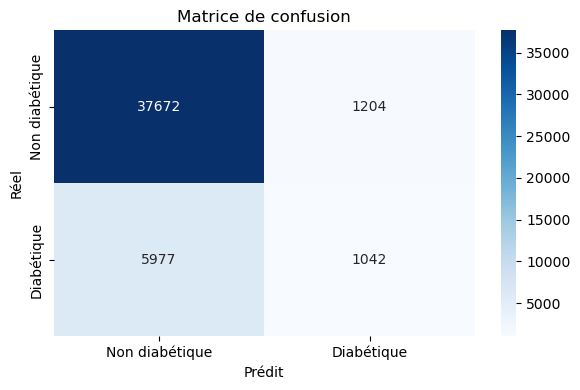

In [5]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non diabétique', 'Diabétique'],
            yticklabels=['Non diabétique', 'Diabétique'])
plt.title('Matrice de confusion')
plt.ylabel('Réel')
plt.xlabel('Prédit')
plt.tight_layout()
plt.show()

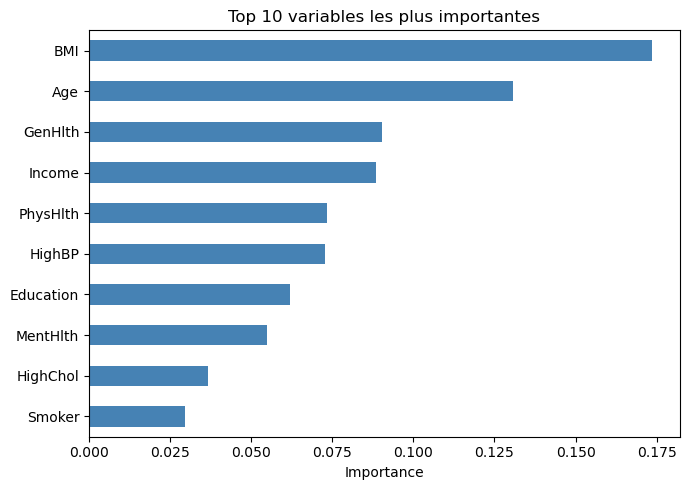

In [6]:
importances = pd.Series(model.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=True).tail(10)

plt.figure(figsize=(7, 5))
importances.plot(kind='barh', color='steelblue')
plt.title('Top 10 variables les plus importantes')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

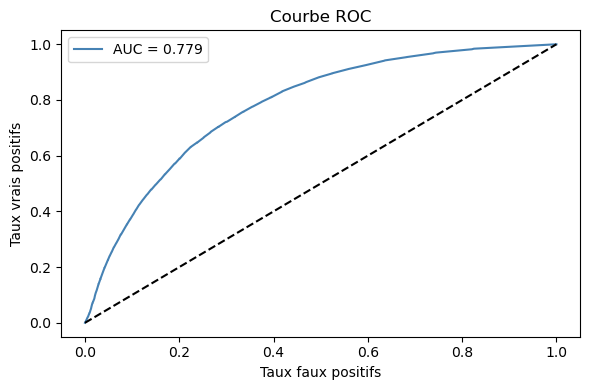

In [7]:
fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:,1])
auc = roc_auc_score(y_test, model.predict_proba(X_test)[:,1])

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='steelblue', label=f'AUC = {auc:.3f}')
plt.plot([0,1], [0,1], 'k--')
plt.title('Courbe ROC')
plt.xlabel('Taux faux positifs')
plt.ylabel('Taux vrais positifs')
plt.legend()
plt.tight_layout()
plt.show()